# Synthetic Data Generation using CTGAN

This notebook explores the use of CTGAN (Conditional Tabular GAN) for generating synthetic tabular data. The goal is to evaluate whether synthetic data preserves the statistical properties and fairness characteristics of the original dataset.

Synthetic data is increasingly used in machine learning to address issues such as data scarcity and privacy. However, since generative models learn from historical data, they may also reproduce or amplify existing biases.

This experiment investigates:
- The quality of synthetic data generated by CTGAN
- Whether bias present in the real dataset is preserved in the synthetic data

## Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ctgan import CTGAN


## Dataset Overview

We load the dataset and inspect its structure to understand variable types and distributions.

# To be Deleted
Add all Dataset info here!!!!

## Test  Dataset Overview

For this test, we shall be using the Adult Income dataset. It contains demographic and employment-related attributes used to predict whether an individual's income exceeds $50K per year.

Sensitive attributes include:
- sex
- race

Target variable:
- income

In [4]:
from ctgan import load_demo

df = load_demo()

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


The dataset is preprocessed and included in the CTGAN library for demonstration purposes. It retains key features such as demographic attributes and income labels, making it suitable for fairness analysis.

## Categorical Variables

We explicitly define categorical variables required by CTGAN.

In [6]:
categorical_columns = [
    'workclass', 'education', 'marital-status',
    'occupation', 'relationship', 'race',
    'sex', 'native-country', 'income'
]

## Model Training

The CTGAN model learns the joint distribution of the dataset.

In [7]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

In [11]:
model = CTGAN(
    epochs=5,
    verbose=True
)

model.fit(df, discrete_columns=categorical_columns)

Gen. (-0.15) | Discrim. (0.11): 100%|██████████| 5/5 [01:44<00:00, 20.81s/it]


## Synthetic Data Generation

In [12]:
synthetic_data = model.sample(5000)

synthetic_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,38,Private,39321,11th,13,Married-civ-spouse,Farming-fishing,Not-in-family,White,Female,-39,4,19,United-States,<=50K
1,38,Private,39460,Some-college,14,Separated,Exec-managerial,Husband,Black,Male,122,5,50,United-States,<=50K
2,45,Private,232045,HS-grad,16,Separated,Farming-fishing,Not-in-family,White,Male,42,6,40,United-States,<=50K
3,20,Private,128007,11th,10,Married-civ-spouse,Prof-specialty,Not-in-family,White,Male,16,3,40,United-States,>50K
4,37,Private,183195,HS-grad,10,Divorced,Handlers-cleaners,Not-in-family,White,Male,-77,-4,40,United-States,<=50K


## Statistical Evaluation

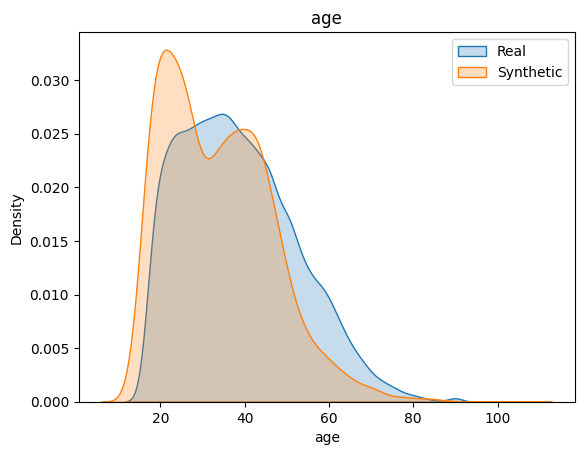

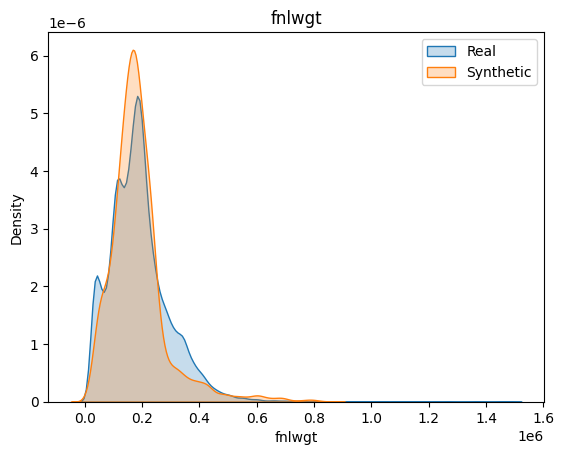

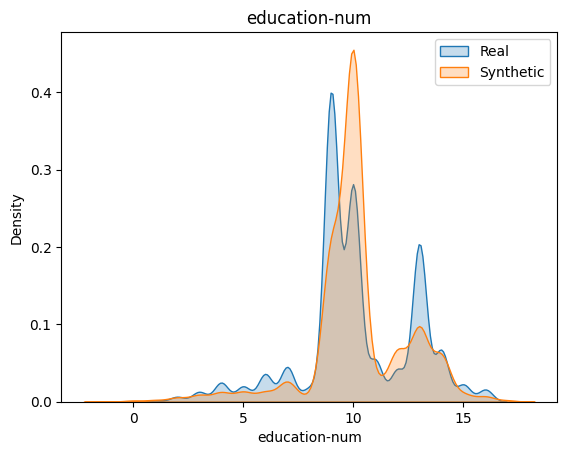

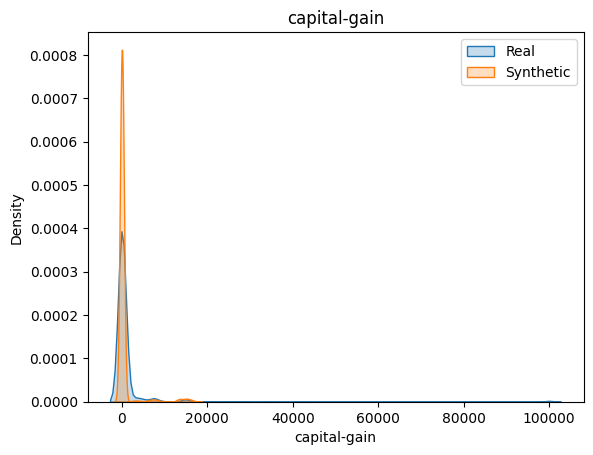

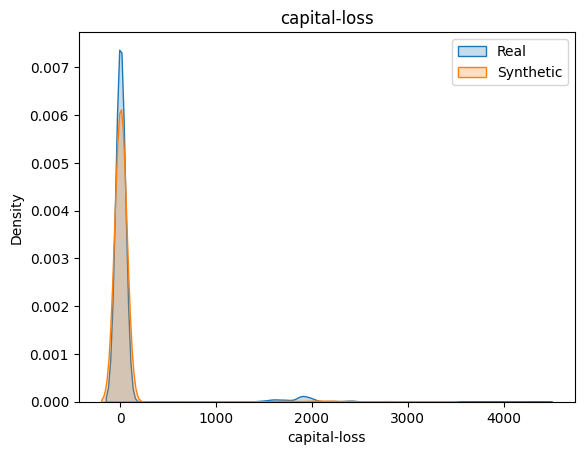

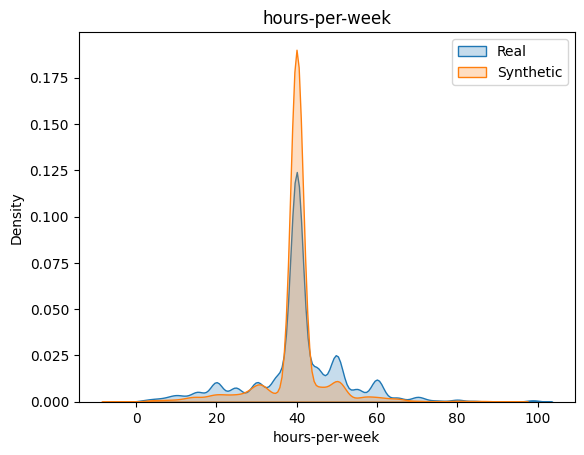

In [13]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    plt.figure()
    sns.kdeplot(df[col], label="Real", fill=True)
    sns.kdeplot(synthetic_data[col], label="Synthetic", fill=True)
    plt.title(col)
    plt.legend()
    plt.show()

## Fairness Analysis

We compare income outcomes across sensitive groups (e.g., sex).

In [14]:
# Convert income to binary
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
synthetic_data['income_binary'] = synthetic_data['income'].apply(lambda x: 1 if '>50K' in x else 0)

In [15]:
#Statistical Parity
real_sp = df.groupby('sex')['income_binary'].mean()
syn_sp = synthetic_data.groupby('sex')['income_binary'].mean()

print("Real:")
print(real_sp)

print("\nSynthetic:")
print(syn_sp)

Real:
sex
Female    0.109461
Male      0.305737
Name: income_binary, dtype: float64

Synthetic:
sex
Female    0.193767
Male      0.248865
Name: income_binary, dtype: float64


In [16]:
#Disparity Gap
real_gap = real_sp.max() - real_sp.min()
syn_gap = syn_sp.max() - syn_sp.min()

print("Real disparity:", real_gap)
print("Synthetic disparity:", syn_gap)

Real disparity: 0.19627598779361352
Synthetic disparity: 0.05509798855082762


## Interpretation

If the disparity in synthetic data closely matches the real data, bias is preserved.

If the disparity increases, bias is amplified. If it decreases, bias is mitigated.

These findings highlight that synthetic data may replicate societal biases present in the original dataset.